In [ ]:
import itertools
import numpy as np


def sigmoid(x):
    return 0.5 * (1.0 + np.tanh(0.5 * x))

def make_donut1d(m, rng):
    m1 = m // 2
    X = np.zeros((2, m)); c = np.zeros(m)
    X[0, :m1] = 0.3 * (2 * rng.random(m1) - 1); c[:m1] = 1.0
    s = np.where(rng.random(m - m1) < 0.5, -1.0, 1.0)
    X[0, m1:] = s * (0.45 + 0.55 * rng.random(m - m1))
    X[1, :] = 0.05 * rng.standard_normal(m)
    return X, c


def make_donut2d(m, rng):
    m1 = m // 2
    first = np.arange(m) < m1
    ang = 2 * np.pi * rng.random(m)
    r = np.where(first, 0.35 * np.sqrt(rng.random(m)), 0.55 + 0.45 * rng.random(m))
    X = np.vstack([r * np.cos(ang), r * np.sin(ang)]) + 0.03 * rng.standard_normal((2, m))
    return X, first.astype(float)


def make_squares(m, rng):
    U = 2 * rng.random((2, m)) - 1
    X = np.sign(U) * (0.05 + 0.95 * np.abs(U))
    return X, (X[0] * X[1] > 0).astype(float)


def make_spiral(m, rng):
    m1 = m // 2
    first = np.arange(m) < m1
    t = 0.15 + 0.85 * rng.random(m)
    th = 3 * np.pi * t
    sgn = np.where(first, 1.0, -1.0)
    X = np.vstack([sgn * t * np.cos(th), sgn * t * np.sin(th)]) + 0.02 * rng.standard_normal((2, m))
    return X, first.astype(float)


DATASET_NAMES = ["donut1d", "donut2d", "squares", "spiral"]
_DATASETS = {"donut1d": (make_donut1d, 500), "donut2d": (make_donut2d, 1000),
             "squares": (make_squares, 1000), "spiral": (make_spiral, 1000)}


def get_data(name, seed=1):
    gen, m = _DATASETS[name]
    Xtr, ctr = gen(m, np.random.default_rng(1000 * seed + 17))
    Xte, cte = gen(m, np.random.default_rng(1000 * seed + 99))
    return Xtr, ctr, Xte, cte


TABLEAUX = {
    "Euler":  (np.zeros((1, 1)), np.array([1.0])),
    "Heun":   (np.array([[0, 0], [1, 0.]]), np.array([.5, .5])),
    "Kutta3": (np.array([[0, 0, 0], [.5, 0, 0], [-1, 2, 0.]]), np.array([1 / 6, 2 / 3, 1 / 6])),
    "Kutta4": (np.array([[0, 0, 0, 0], [.5, 0, 0, 0], [0, .5, 0, 0], [0, 0, 1, 0.]]),
               np.array([1 / 6, 1 / 3, 1 / 3, 1 / 6])),
}


class Model:

    def __init__(self, kind, n, N, T=1.0, tab="Euler"):
        self.kind, self.n, self.N, self.T, self.tab = kind, n, N, T, tab
        self.A, self.b = TABLEAUX[tab]
        self.train_alpha = kind in ("odenet", "odenet_simplex")
        self.simplex = kind == "odenet_simplex"
        self.h = 1.0 if self.train_alpha else T / N  
        self.per = n * n + n
        self.nparams = N * self.per + N + n + 1

    def K(self, th, j):
        o = j * self.per
        return th[o:o + self.n ** 2].reshape(self.n, self.n)

    def beta(self, th, j):
        o = j * self.per + self.n ** 2
        return th[o:o + self.n]

    @property
    def sl_alpha(self):
        return slice(self.N * self.per, self.N * self.per + self.N)

    @property
    def sl_W(self):
        o = self.N * self.per + self.N
        return slice(o, o + self.n)

    @property
    def i_mu(self):
        return self.N * self.per + self.N + self.n

    def alpha(self, th, j):
        return th[self.N * self.per + j] if self.train_alpha else 1.0

    def init_params(self, rng, sK=0.7, sb=0.1, sW=0.5):
        th = np.zeros(self.nparams)
        for j in range(self.N):
            o = j * self.per
            th[o:o + self.n ** 2] = sK * rng.standard_normal(self.n ** 2)
            th[o + self.n ** 2:o + self.per] = sb * rng.standard_normal(self.n)
        if self.train_alpha:
            th[self.sl_alpha] = self.T / self.N
        th[self.sl_W] = sW * rng.standard_normal(self.n)
        return th


def Net(n, N):
    return Model("net", n, N)


def ResNet(n, N, T=1.0, tab="Euler"):
    return Model("resnet", n, N, T, tab)


def ODENet(n, N, T=1.0, tab="Euler", simplex=False):
    return Model("odenet_simplex" if simplex else "odenet", n, N, T, tab)


def ode_methods():
    return [
        ("Net",            lambda: Net(2, 20)),
        ("ResNet",         lambda: ResNet(2, 20)),
        ("ODENet",         lambda: ODENet(2, 20)),
        ("ODENet+Simplex", lambda: ODENet(2, 20, simplex=True)),
        ("RK1-Euler",      lambda: ResNet(2, 15, tab="Euler")),
        ("RK2-Heun",       lambda: ResNet(2, 15, tab="Heun")),
        ("RK3-Kutta",      lambda: ResNet(2, 15, tab="Kutta3")),
        ("RK4-Kutta",      lambda: ResNet(2, 15, tab="Kutta4")),
    ]


def slug(s):
    import re
    return re.sub(r"[^A-Za-z0-9]+", "_", s).lower()


def layer_forward(M, K, beta, alpha, Y):
    bcol = beta[:, None]
    if M.kind == "net":
        S = np.tanh(K @ Y + bcol)
        return S, ([Y], [S])
    A, b, h = M.A, M.b, M.h
    s = len(b)
    Ys, Ss, F = [], [], []
    for i in range(s):
        Yi = Y.copy()
        for l in range(i):
            if A[i, l] != 0.0:
                Yi += (h * A[i, l]) * F[l]
        S = np.tanh(K @ Yi + bcol)
        Ys.append(Yi); Ss.append(S); F.append(alpha * S)
    Yn = Y.copy()
    for i in range(s):
        Yn += (h * b[i]) * F[i]
    return Yn, (Ys, Ss)


def forward(M, th, X, keep=True):
    Y = X
    caches = []
    for j in range(M.N):
        Y, cache = layer_forward(M, M.K(th, j), M.beta(th, j), M.alpha(th, j), Y)
        if keep:
            caches.append(cache)
    return Y, caches


def head(M, th, Y):
    return sigmoid(th[M.sl_W][None, :] @ Y + th[M.i_mu])    


def loss(M, th, X, c):
    Y, _ = forward(M, th, X, keep=False)
    q = head(M, th, Y)
    return float(np.sum((q - c[None, :]) ** 2) / (2 * X.shape[1]))


def evaluate(M, th, X, c):
    Y, _ = forward(M, th, X, keep=False)
    q = head(M, th, Y)
    return (float(np.sum((q - c[None, :]) ** 2) / (2 * X.shape[1])),
            float(np.mean((q[0] > 0.5) == (c > 0.5))))


def predict_prob(M, th, X):
    Y, _ = forward(M, th, X, keep=False)
    return head(M, th, Y)[0]


def predict(M, th, X):
    return (predict_prob(M, th, X) > 0.5).astype(float)


def layer_states(M, th, X):
    out = [X.copy()]
    Y = X
    for j in range(M.N):
        Y, _ = layer_forward(M, M.K(th, j), M.beta(th, j), M.alpha(th, j), Y)
        out.append(Y.copy())
    return out

def layer_backward(M, K, alpha, cache, Pp, gK, gb):
    Ys, Ss = cache
    if M.kind == "net":
        D = (1 - Ss[0] ** 2) * Pp
        gK += D @ Ys[0].T
        gb += D.sum(axis=1)
        return K.T @ D, 0.0
    A, b, h = M.A, M.b, M.h
    s = len(b)
    G = [None] * s
    ga = 0.0
    for i in range(s - 1, -1, -1):
        Lam = (h * b[i]) * Pp
        for k in range(i + 1, s):
            if A[k, i] != 0.0:
                Lam = Lam + (h * A[k, i]) * G[k]
        S = Ss[i]
        D = (1 - S ** 2) * Lam
        gK += alpha * (D @ Ys[i].T)
        gb += alpha * D.sum(axis=1)
        ga += float(np.sum(S * Lam))
        G[i] = alpha * (K.T @ D)
    P = Pp.copy()
    for i in range(s):
        P += G[i]
    return P, ga


def loss_grad(g, M, th, X, c):
    m = X.shape[1]
    g[:] = 0.0
    Y, caches = forward(M, th, X)
    W = th[M.sl_W][None, :]
    q = sigmoid(W @ Y + th[M.i_mu])
    r = q - c[None, :]
    J = float(np.sum(r ** 2) / (2 * m))
    gam = r * q * (1 - q) / m                     
    g[M.sl_W] += (gam @ Y.T)[0]                     
    g[M.i_mu] += gam.sum()                       
    P = W.T @ gam                                   
    for j in range(M.N - 1, -1, -1):
        o = j * M.per
        gK = g[o:o + M.n ** 2].reshape(M.n, M.n)  
        gb = g[o + M.n ** 2:o + M.per]
        P, ga = layer_backward(M, M.K(th, j), M.alpha(th, j), caches[j], P, gK, gb)
        if M.train_alpha:
            g[M.N * M.per + j] += ga
    return J


def n_active_layers(M, th):
    return int(np.sum(np.abs(th[M.sl_alpha]) > 1e-10)) if M.simplex else M.N


def effective_params(M, th):
    L = n_active_layers(M, th)
    return L * (M.n ** 2 + M.n + (1 if M.train_alpha else 0)) + M.n + 1


def forward_flops(M, th):
    s = 1 if M.kind == "net" else len(M.b)
    return n_active_layers(M, th) * s * (2 * M.n ** 2 + 3 * M.n) + 2 * M.n


def proj_simplex(v, r):
    u = np.sort(v)[::-1]
    css = np.cumsum(u)
    idx = np.arange(1, len(v) + 1)
    rho = np.nonzero(u - (css - r) / idx > 0)[0][-1]
    tau = (css[rho] - r) / (rho + 1)
    return np.maximum(v - tau, 0.0)


def default_proj(M):
    if not M.simplex:
        return None

    def proj(th):
        th[M.sl_alpha] = proj_simplex(th[M.sl_alpha], M.T)
        return th
    return proj


class History:
    def __init__(self):
        self.iter, self.train_loss, self.test_loss = [], [], []
        self.train_acc, self.test_acc, self.L = [], [], []

    def rows(self):
        return list(zip(self.iter, self.train_loss, self.test_loss, self.train_acc, self.test_acc, self.L))


def train(M, th0, X, c, iters=2000, L0=1.0, rho_up=2.0, rho_down=0.9, Xte=None, cte=None,
          proj="default", log_every=10, verbose=False):
    proj_fn = default_proj(M) if isinstance(proj, str) else proj
    th = th0.copy()
    if proj_fn is not None:
        proj_fn(th)
    g = np.zeros_like(th)
    phi = loss_grad(g, M, th, X, c)
    L = L0
    hist = History()

    def record(k):
        _, tra = evaluate(M, th, X, c)
        tel, tea = evaluate(M, th, Xte, cte) if Xte is not None else (np.nan, np.nan)
        hist.iter.append(k); hist.train_loss.append(phi); hist.test_loss.append(tel)
        hist.train_acc.append(tra); hist.test_acc.append(tea); hist.L.append(L)
        if verbose:
            print(f"  it {k:5d}  J = {phi:.3e}  acc_tr = {tra:.3f}  acc_te = {tea:.3f}  L = {L:.2e}")

    record(0)
    for k in range(1, iters + 1):
        accepted = False
        for _ in range(60):                         
            thn = th - g / L
            if proj_fn is not None:
                proj_fn(thn)
            d = thn - th
            phin = loss(M, thn, X, c)
            if phin <= phi + g @ d + 0.5 * L * (d @ d) + 1e-14:
                accepted = True
                break
            L *= rho_up
        if not accepted:
            break
        stationary = np.linalg.norm(d) < 1e-14
        th = thn
        phi = loss_grad(g, M, th, X, c)
        L *= rho_down
        if k <= 10 or k % log_every == 0 or k == iters:
            record(k)
        if stationary:
            break
    return th, hist


def poly_features(X, exps):
    return np.vstack([np.prod(X ** np.array(e)[:, None], axis=0) for e in exps])


class LogReg:

    def __init__(self, degree=1, lam=1e-4, iters=100):
        self.degree, self.lam, self.iters = degree, lam, iters

    def fit(self, X, c):
        n = X.shape[0]
        self.exps = [e for e in itertools.product(range(self.degree + 1), repeat=n)
                     if 1 <= sum(e) <= self.degree]
        Phi = poly_features(X, self.exps)
        A = np.vstack([Phi, np.ones((1, X.shape[1]))])
        p1, m = A.shape
        reg = self.lam * np.r_[np.ones(p1 - 1), 0.0]
        w = np.zeros(p1)
        for _ in range(self.iters):
            q = sigmoid(A.T @ w)
            g = A @ (q - c) / m + reg * w
            H = (A * (q * (1 - q))) @ A.T / m + np.diag(reg) + 1e-10 * np.eye(p1)
            d = np.linalg.solve(H, g)
            w -= d
            if np.linalg.norm(d) < 1e-10:
                break
        self.w = w
        return self

    def prob(self, X):
        A = np.vstack([poly_features(X, self.exps), np.ones((1, X.shape[1]))])
        return sigmoid(A.T @ self.w)

    @property
    def n_params(self):
        return len(self.w)


class DecisionTree:

    def __init__(self, max_depth=8, min_leaf=5):
        self.max_depth, self.min_leaf = max_depth, min_leaf

    def fit(self, X, c):
        self.nodes = []              
        self._build(X, c, np.arange(X.shape[1]), 0)
        return self

    def _build(self, X, c, idx, depth):
        p = c[idx].mean()
        self.nodes.append([-1, 0.0, -1, -1, p])
        me = len(self.nodes) - 1
        m = len(idx)
        if depth >= self.max_depth or m < 2 * self.min_leaf or p in (0.0, 1.0):
            return me
        ml = self.min_leaf
        parent = 2 * p * (1 - p)
        best_gain, best_f, best_thr = 1e-12, -1, 0.0
        ks = np.arange(ml, m - ml + 1)        
        for f in range(X.shape[0]):
            xf = X[f, idx]
            order = np.argsort(xf, kind="stable")
            xs = xf[order]
            cs = np.cumsum(c[idx][order])
            tot = cs[-1]
            valid = xs[ks - 1] != xs[ks]
            nl, nr = ks, m - ks
            pl, pr = cs[ks - 1] / nl, (tot - cs[ks - 1]) / nr
            gain = parent - (nl * 2 * pl * (1 - pl) + nr * 2 * pr * (1 - pr)) / m
            gain = np.where(valid, gain, -np.inf)
            j = int(np.argmax(gain))
            if gain[j] > best_gain:
                best_gain, best_f, best_thr = gain[j], f, (xs[ks[j] - 1] + xs[ks[j]]) / 2
        if best_f < 0:
            return me
        mask = X[best_f, idx] <= best_thr
        left = self._build(X, c, idx[mask], depth + 1)
        right = self._build(X, c, idx[~mask], depth + 1)
        self.nodes[me][:4] = [best_f, best_thr, left, right]
        return me

    def prob(self, X):
        out = np.zeros(X.shape[1])
        for j in range(X.shape[1]):
            k = 0
            while self.nodes[k][0] >= 0:
                f, thr, l, r, _ = self.nodes[k]
                k = l if X[f, j] <= thr else r
            out[j] = self.nodes[k][4]
        return out

    def depth(self, k=0):
        nd = self.nodes[k]
        return 0 if nd[0] < 0 else 1 + max(self.depth(nd[2]), self.depth(nd[3]))

    @property
    def n_params(self):
        internos = sum(1 for nd in self.nodes if nd[0] >= 0)
        return 3 * internos + (len(self.nodes) - internos)


class KNN:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, c):
        self.X, self.c = X, c
        return self

    def prob(self, Xq):
        d = ((Xq[:, :, None] - self.X[:, None, :]) ** 2).sum(axis=0)    
        idx = np.argpartition(d, self.k - 1, axis=1)[:, :self.k]
        return self.c[idx].mean(axis=1)

    @property
    def n_params(self):
        return self.X.size


def prob_loss(q, c):
    return float(np.sum((q - c) ** 2) / (2 * len(c)))


def prob_acc(q, c):
    return float(np.mean((q > 0.5) == (c > 0.5)))

def write_table(path, header, rows):
    with open(path, "w", encoding="utf-8") as f:
        f.write(",".join(header) + "\n")
        for r in rows:
            f.write(",".join(str(x) for x in r) + "\n")


def read_numeric_csv(path):
    return np.loadtxt(path, delimiter=",", skiprows=1, ndmin=2)


def save_theta(path, th):
    write_table(path, ["theta"], [(x,) for x in th])


def load_theta(path):
    return read_numeric_csv(path).ravel()

In [ ]:
import numpy as np


def fd_grad(M, th, X, c, eps=1e-6):
    g = np.zeros_like(th)
    for i in range(len(th)):
        e = np.zeros_like(th); e[i] = eps
        g[i] = (loss(M, th + e, X, c) - loss(M, th - e, X, c)) / (2 * eps)
    return g


rng = np.random.default_rng(0)
n, N, m = 2, 4, 30
X = rng.standard_normal((n, m))
c = (rng.random(m) > 0.5).astype(float)

modelos = [
    ("Net",                   Net(n, N)),
    ("ResNet  (Euler)",       ResNet(n, N, tab="Euler")),
    ("ResNet  (Heun)",        ResNet(n, N, tab="Heun")),
    ("ResNet  (Kutta3)",      ResNet(n, N, tab="Kutta3")),
    ("ResNet  (Kutta4)",      ResNet(n, N, tab="Kutta4")),
    ("ODENet  (Euler)",       ODENet(n, N, tab="Euler")),
    ("ODENet  (Kutta4)",      ODENet(n, N, tab="Kutta4")),
    ("ODENet+Simplex (Heun)", ODENet(n, N, tab="Heun", simplex=True)),
]

print("Verificación del gradiente (adjunto vs. diferencias finitas)")
print("-" * 62)
peor = 0.0
for nombre, M in modelos:
    th = M.init_params(rng)
    if M.train_alpha:
        th[M.sl_alpha] += 0.1 * rng.standard_normal(M.N)      
    g = np.zeros_like(th)
    J = loss_grad(g, M, th, X, c)
    gf = fd_grad(M, th, X, c)
    err = np.linalg.norm(g - gf) / max(np.linalg.norm(gf), 1e-14)
    peor = max(peor, err)
    print(f"{nombre:24s}  J = {J:.6f}   error relativo = {err:.2e}")
print("-" * 62)
print(f"OK: el gradiente adjunto es exacto (peor error = {peor:.2g})" if peor < 1e-6
      else f"ATENCIÓN: discrepancia en el gradiente (peor error = {peor})")

print("\nProyección sobre el símplex {α ≥ 0, Σα = T}")
v = np.array([0.9, -0.3, 0.4, 0.05, 0.2])
w = proj_simplex(v, 1.0)
print(f"  v = {v}\n  P(v) = {np.round(w, 4)}   Σ = {w.sum():.12f}   mín = {w.min():.3f}")
assert abs(w.sum() - 1) < 1e-12 and w.min() >= 0

Verificación del gradiente (adjunto vs. diferencias finitas)
--------------------------------------------------------------
Net                       J = 0.125150   error relativo = 5.96e-09
ResNet  (Euler)           J = 0.137015   error relativo = 2.13e-09
ResNet  (Heun)            J = 0.145872   error relativo = 1.12e-09
ResNet  (Kutta3)          J = 0.170326   error relativo = 1.70e-09
ResNet  (Kutta4)          J = 0.138751   error relativo = 8.00e-10
ODENet  (Euler)           J = 0.131505   error relativo = 1.18e-09
ODENet  (Kutta4)          J = 0.156491   error relativo = 1.46e-09
ODENet+Simplex (Heun)     J = 0.230234   error relativo = 1.15e-09
--------------------------------------------------------------
OK: el gradiente adjunto es exacto (peor error = 6e-09)

Proyección sobre el símplex {α ≥ 0, Σα = T}
  v = [ 0.9  -0.3   0.4   0.05  0.2 ]
  P(v) = [0.7333 0.     0.2333 0.     0.0333]   Σ = 1.000000000000   mín = 0.000


In [ ]:
import os
import time
import numpy as np

iters = 2000
nseeds = 3

outdir = os.path.join(os.getcwd(), "results")
os.makedirs(outdir, exist_ok=True)

BASELINES = [
    ("LogReg(g=1)", lambda: LogReg(degree=1)),
    ("LogReg(g=5)", lambda: LogReg(degree=5)),
    ("Arbol(d=8)",  lambda: DecisionTree(max_depth=8, min_leaf=5)),
    ("kNN(k=5)",    lambda: KNN(k=5)),
]


def best_time(f, reps):
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); f(); ts.append(time.perf_counter() - t)
    return min(ts)


def run_ode(mname, ctor, data, seed):
    Xtr, ctr, Xte, cte = data
    M = ctor()
    th0 = M.init_params(np.random.default_rng(seed))
    t0 = time.perf_counter()
    th, hist = train(M, th0, Xtr, ctr, iters=iters, Xte=Xte, cte=cte, log_every=10)
    t_train = time.perf_counter() - t0
    tl, ta = evaluate(M, th, Xtr, ctr)
    vl, va = evaluate(M, th, Xte, cte)
    tp = best_time(lambda: predict(M, th, Xte), 5)
    row = dict(method=mname, train_acc=ta, test_acc=va, train_loss=tl, test_loss=vl, train_s=t_train,
               pred_us=1e6 * tp / Xte.shape[1], params=effective_params(M, th),
               layers=n_active_layers(M, th), flops=forward_flops(M, th))
    return row, M, th, hist


def run_baseline(mname, ctor, data):
    Xtr, ctr, Xte, cte = data
    mdl = ctor()
    t0 = time.perf_counter()
    mdl.fit(Xtr, ctr)
    t_train = time.perf_counter() - t0
    qtr, qte = mdl.prob(Xtr), mdl.prob(Xte)
    tp = best_time(lambda: mdl.prob(Xte), 3)
    if isinstance(mdl, LogReg):
        flops = 2 * mdl.n_params
    elif isinstance(mdl, DecisionTree):
        flops = mdl.depth()
    else:
        flops = Xtr.shape[1] * 3 * Xtr.shape[0]
    return dict(method=mname, train_acc=prob_acc(qtr, ctr), test_acc=prob_acc(qte, cte),
                train_loss=prob_loss(qtr, ctr), test_loss=prob_loss(qte, cte), train_s=t_train,
                pred_us=1e6 * tp / Xte.shape[1], params=mdl.n_params, layers=0, flops=flops)


header = ["dataset", "method", "seed", "train_acc", "test_acc", "train_loss", "test_loss",
          "train_s", "pred_us", "params", "layers", "flops"]
rows, resumen = [], {}


def guardar(name, seed, r):
    rows.append((name, r["method"], seed, r["train_acc"], r["test_acc"], r["train_loss"], r["test_loss"],
                 r["train_s"], r["pred_us"], r["params"], r["layers"], r["flops"]))
    resumen.setdefault((name, r["method"]), []).append(r)


for name in DATASET_NAMES:
    for seed in range(1, nseeds + 1):
        data = get_data(name, seed)
        print(f"\n=== {name} (semilla {seed}): m = {data[0].shape[1]} datos de entrenamiento ===", flush=True)
        for mname, ctor in ode_methods():
            r, M, th, hist = run_ode(mname, ctor, data, seed)
            guardar(name, seed, r)
            print(f"  {mname:15s}  acc train/test = {r['train_acc']:.3f} / {r['test_acc']:.3f}   "
                  f"J = {r['train_loss']:.2e}   tiempo = {r['train_s']:6.1f} s", flush=True)
            if seed == 1:
                tag = f"{name}_{slug(mname)}"
                write_table(os.path.join(outdir, f"hist_{tag}.csv"),
                            ["iter", "train_loss", "test_loss", "train_acc", "test_acc", "L"], hist.rows())
                save_theta(os.path.join(outdir, f"theta_{tag}.csv"), th)
        for mname, ctor in BASELINES:
            r = run_baseline(mname, ctor, data)
            guardar(name, seed, r)
            print(f"  {mname:15s}  acc train/test = {r['train_acc']:.3f} / {r['test_acc']:.3f}   "
                  f"J = {r['train_loss']:.2e}   tiempo = {r['train_s']:6.3f} s", flush=True)
        write_table(os.path.join(outdir, "resultados.csv"), header, rows)     # guardado incremental

print("\n" + "=" * 96)
print(f"RESUMEN (media ± desv. est. sobre {nseeds} semilla(s)); iteraciones de GD = {iters}")
print("=" * 96)
for name in DATASET_NAMES:
    print(f"\n{name}")
    print(f"  {'método':15s} {'acc. train':17s} {'acc. test':17s} {'t_train[s]':>10s} {'pred[µs]':>9s} {'params':>8s}")
    for m in dict.fromkeys(r[1] for r in rows if r[0] == name):
        rs = resumen[(name, m)]
        f = lambda k: np.array([x[k] for x in rs])
        print(f"  {m:15s} {f('train_acc').mean():6.3f} ± {f('train_acc').std():<8.3f} "
              f"{f('test_acc').mean():6.3f} ± {f('test_acc').std():<8.3f} {f('train_s').mean():10.2f} "
              f"{f('pred_us').mean():9.2f} {int(round(f('params').mean())):8d}")
print("\nResultados guardados en:", outdir)


=== donut1d (semilla 1): m = 500 datos de entrenamiento ===
  Net              acc train/test = 0.466 / 0.506   J = 1.25e-01   tiempo =    3.0 s
  ResNet           acc train/test = 1.000 / 1.000   J = 0.00e+00   tiempo =    3.9 s
  ODENet           acc train/test = 1.000 / 1.000   J = 4.08e-32   tiempo =    4.4 s
  ODENet+Simplex   acc train/test = 1.000 / 1.000   J = 5.06e-05   tiempo =    4.4 s
  RK1-Euler        acc train/test = 1.000 / 1.000   J = 2.43e-23   tiempo =    3.9 s
  RK2-Heun         acc train/test = 1.000 / 1.000   J = 9.65e-23   tiempo =    6.8 s
  RK3-Kutta        acc train/test = 1.000 / 1.000   J = 3.68e-21   tiempo =   10.8 s
  RK4-Kutta        acc train/test = 1.000 / 1.000   J = 5.50e-20   tiempo =   13.9 s
  LogReg(g=1)      acc train/test = 0.536 / 0.522   J = 1.25e-01   tiempo =  0.014 s
  LogReg(g=5)      acc train/test = 1.000 / 1.000   J = 1.19e-03   tiempo =  0.004 s
  Arbol(d=8)       acc train/test = 1.000 / 1.000   J = 0.00e+00   tiempo =  0.007 s
  kN

In [ ]:
import time
import numpy as np

Npasos, Tfin = 20, 1.0
h = Tfin / Npasos
W0, mu0 = 4.0, 0.0
kmax, bmax = 5.0, 2.0
x0 = np.array([-0.1, 0.1])       
c = np.array([0.0, 1.0])


def sig(x):
    return 0.5 * (1 + np.tanh(0.5 * x))


def g_term(ya, yb):
    return ((sig(W0 * ya + mu0) - c[0]) ** 2 + (sig(W0 * yb + mu0) - c[1]) ** 2) / (2 * 2)


Ng, ymin, ymax = 151, -1.5, 1.5
ys = np.linspace(ymin, ymax, Ng)
dy = ys[1] - ys[0]
ctrl = np.array([(k, b) for k in np.linspace(-kmax, kmax, 21) for b in np.linspace(-bmax, bmax, 9)])
nu = len(ctrl)
Ftab = np.tanh(np.outer(ys, ctrl[:, 0]) + ctrl[:, 1][None, :])      
YA, YB = np.meshgrid(ys, ys, indexing="ij")


def interp(V, a, b):
    fa = np.clip((a - ymin) / dy, 0.0, Ng - 1 - 1e-9)
    fb = np.clip((b - ymin) / dy, 0.0, Ng - 1 - 1e-9)
    ia, ib = fa.astype(int), fb.astype(int)
    ta, tb = fa - ia, fb - ib
    return ((1 - ta) * (1 - tb) * V[ia, ib] + ta * (1 - tb) * V[ia + 1, ib]
            + (1 - ta) * tb * V[ia, ib + 1] + ta * tb * V[ia + 1, ib + 1])


print(f"Resolviendo HJB discreta (programación dinámica) en grilla {Ng}x{Ng}, {nu} controles, {Npasos} pasos ...")
t0 = time.perf_counter()
Vs = [None] * (Npasos + 1)
pol = [None] * Npasos
Vs[Npasos] = g_term(YA, YB)
for s in range(Npasos - 1, -1, -1):
    Vn = Vs[s + 1]
    best = np.full((Ng, Ng), np.inf)
    arg = np.zeros((Ng, Ng), dtype=int)
    for iu in range(nu):
        v = interp(Vn, YA + h * Ftab[:, iu][:, None], YB + h * Ftab[:, iu][None, :])
        upd = v < best
        best = np.where(upd, v, best)
        arg = np.where(upd, iu, arg)
    Vs[s], pol[s] = best, arg
V0 = float(interp(Vs[0], np.array([x0[0]]), np.array([x0[1]]))[0])
print(f"  tiempo DP = {time.perf_counter() - t0:.1f} s")

y = x0.copy()
print("\nControl óptimo por feedback (argmin de HJB) a lo largo de la trayectoria óptima:")
for s in range(Npasos):
    ia = int(np.clip(round((y[0] - ymin) / dy), 0, Ng - 1))
    ib = int(np.clip(round((y[1] - ymin) / dy), 0, Ng - 1))
    k, b = ctrl[pol[s][ia, ib]]
    if s + 1 in (1, 5, 10, 15, 20):
        print(f"  paso {s + 1:2d}: y = ({y[0]:6.3f}, {y[1]:6.3f})   u* = (k = {k:5.2f}, β = {b:5.2f})")
    y = y + h * np.tanh(k * y + b)
J_fb = float(g_term(y[0], y[1]))

M = ResNet(1, Npasos, T=Tfin)
X = x0.reshape(1, 2)


def proyectar(th):
    for j in range(M.N):
        o = j * M.per
        th[o] = np.clip(th[o], -kmax, kmax)
        th[o + 1] = np.clip(th[o + 1], -bmax, bmax)
    th[M.sl_W] = W0
    th[M.i_mu] = mu0
    return th


mejor = np.inf
for seed in range(1, 11):
    th0 = M.init_params(np.random.default_rng(seed), sK=2.0, sb=0.5)
    th, _ = train(M, th0, X, c, iters=3000, proj=proyectar, log_every=1000)
    mejor = min(mejor, loss(M, th, X, c))

J0 = float(g_term(x0[0], x0[1]))
print("\nComparación de costos (todos con los mismos límites de control):")
print(f"  costo sin control (u = 0)                  : {J0:.3e}")
print(f"  HJB/DP  V_0(x0)  (óptimo global en grilla) : {V0:.3e}")
print(f"  HJB/DP  simulando el feedback óptimo       : {J_fb:.3e}")
print(f"  PMP + adjunto + GD proyectado (mejor de 10): {mejor:.3e}")
print("  (la DP usa una grilla de controles y de estados; el GD usa controles continuos,")
print("   por eso pueden diferir ligeramente; ambos deben ser mucho menores que el costo inicial)")

print(f"\nMemoria para guardar V sobre una grilla de {Ng} puntos por coordenada (dimensión = n·m):")
for mm in (2, 3, 4, 5, 10):
    byt = float(Ng) ** mm * 8
    u = f"{byt / 1e12:.1e} TB" if byt > 1e12 else f"{byt / 1e9:.1f} GB" if byt > 1e9 else f"{byt / 1e6:.1f} MB"
    print(f"  m = {mm:2d} datos (n = 1):  {u}")
print(f"  => con m = 1000 datos y n = 2 la grilla tendría {Ng}^2000 nodos: HJB no es viable;")
print("     se usa PMP (adjunto) cuyo costo crece linealmente con m.")

Resolviendo HJB discreta (programación dinámica) en grilla 151x151, 189 controles, 20 pasos ...
  tiempo DP = 5.6 s

Control óptimo por feedback (argmin de HJB) a lo largo de la trayectoria óptima:
  paso  1: y = (-0.100,  0.100)   u* = (k =  5.00, β =  0.00)
  paso  5: y = (-0.218,  0.218)   u* = (k =  5.00, β =  0.00)
  paso 10: y = (-0.442,  0.442)   u* = (k =  5.00, β =  0.00)
  paso 15: y = (-0.689,  0.689)   u* = (k =  5.00, β =  0.00)
  paso 20: y = (-0.939,  0.939)   u* = (k =  5.00, β =  0.00)

Comparación de costos (todos con los mismos límites de control):
  costo sin control (u = 0)                  : 8.053e-02
  HJB/DP  V_0(x0)  (óptimo global en grilla) : 1.907e-04
  HJB/DP  simulando el feedback óptimo       : 1.769e-04
  PMP + adjunto + GD proyectado (mejor de 10): 1.769e-04
  (la DP usa una grilla de controles y de estados; el GD usa controles continuos,
   por eso pueden diferir ligeramente; ambos deben ser mucho menores que el costo inicial)

Memoria para guardar V s

figuras listas: donut1d
figuras listas: donut2d
figuras listas: squares
figuras listas: spiral
Figuras guardadas en /content/results/figs


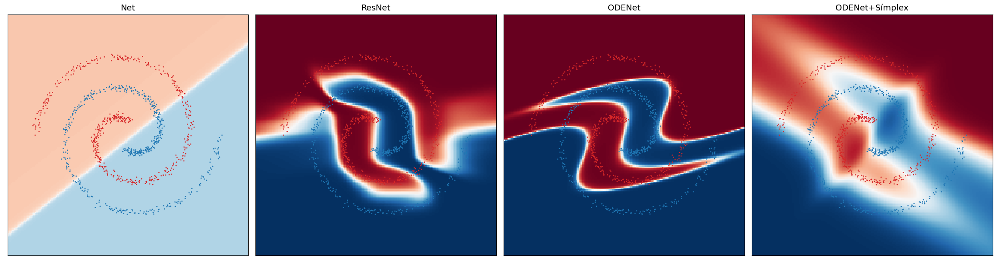

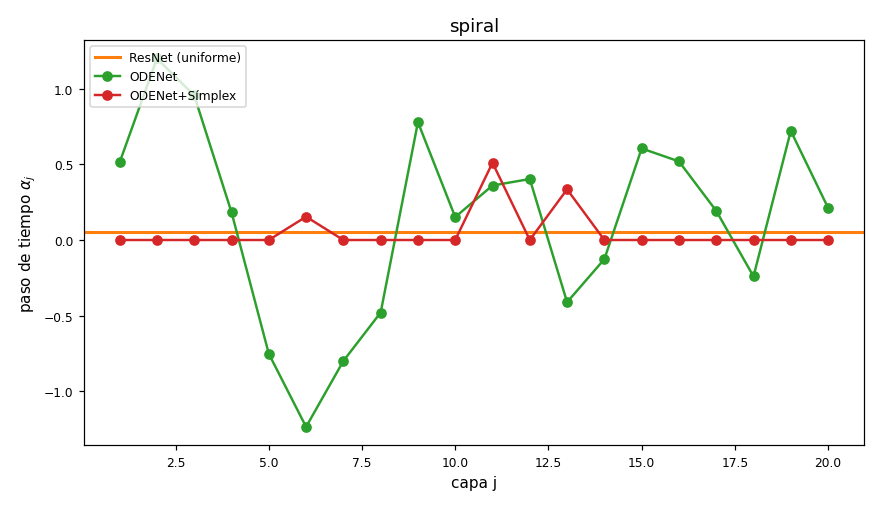

In [ ]:
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

poster = False  # Cambiar a True para generar versiones con fuentes grandes en results/figs_poster
here = os.getcwd()
resdir = os.path.join(here, "results")
figdir = os.path.join(resdir, "figs_poster" if poster else "figs")
os.makedirs(figdir, exist_ok=True)

FS = 26 if poster else 10
plt.rcParams.update({"font.size": FS, "axes.titlesize": FS + 2, "axes.labelsize": FS,
                     "xtick.labelsize": FS - 2, "ytick.labelsize": FS - 2, "legend.fontsize": FS - 3,
                     "lines.linewidth": 3 if poster else 1.6, "axes.grid": False})
METODOS = dict(ode_methods())
ARQ = ["Net", "ResNet", "ODENet", "ODENet+Simplex"]
RK = ["RK1-Euler", "RK2-Heun", "RK3-Kutta", "RK4-Kutta"]
TITULO = {"ODENet+Simplex": "ODENet+Símplex"}
col = lambda c: np.where(c > 0.5, "#d62728", "#1f77b4")


def cargar(d, m):
    return METODOS[m](), load_theta(os.path.join(resdir, f"theta_{d}_{slug(m)}.csv"))


def panel_pred(ax, M, th, Xtr, ctr, titulo, lim=1.3, res=160):
    xs = np.linspace(-lim, lim, res)
    GX, GY = np.meshgrid(xs, xs)
    Z = predict_prob(M, th, np.vstack([GX.ravel(), GY.ravel()])).reshape(res, res)
    ax.imshow(Z, extent=(-lim, lim, -lim, lim), origin="lower", cmap="RdBu_r", vmin=0, vmax=1)
    ax.scatter(Xtr[0], Xtr[1], c=col(ctr), s=6 if poster else 3, linewidths=0)
    ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)


def fila(d, metodos, nombre):
    Xtr, ctr, _, _ = get_data(d, 1)
    fig, axs = plt.subplots(1, 4, figsize=(16, 4.6) if poster else (20, 5.4))
    for ax, m in zip(axs, metodos):
        M, th = cargar(d, m)
        panel_pred(ax, M, th, Xtr, ctr, TITULO.get(m, m))
    fig.tight_layout(); fig.savefig(os.path.join(figdir, nombre), dpi=110); plt.close(fig)


def transf(d, metodos, nombre, nsnap=4):
    Xtr, ctr, _, _ = get_data(d, 1)
    fig, axs = plt.subplots(len(metodos), nsnap, figsize=(3.6 * nsnap, 3.3 * len(metodos)))
    for r, m in enumerate(metodos):
        M, th = cargar(d, m)
        Ys = layer_states(M, th, Xtr)
        for k, j in enumerate(np.round(np.linspace(0, M.N, nsnap)).astype(int)):
            ax = axs[r, k]
            ax.scatter(Ys[j][0], Ys[j][1], c=col(ctr), s=3, linewidths=0)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title((f"{TITULO.get(m, m)} — capa {j}" if k == 0 else f"capa {j}"), fontsize=FS - 2)
    fig.tight_layout(); fig.savefig(os.path.join(figdir, nombre), dpi=110); plt.close(fig)


def historia(d, metodos, nombre):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
    for i, m in enumerate(metodos):
        H = read_numeric_csv(os.path.join(resdir, f"hist_{d}_{slug(m)}.csv"))
        it = np.maximum(H[:, 0], 1)
        a1.loglog(it, np.maximum(H[:, 1], 1e-12), color=f"C{i}", label=TITULO.get(m, m))
        a1.loglog(it, np.maximum(H[:, 2], 1e-12), color=f"C{i}", ls="--", lw=1)
        a2.semilogx(it, H[:, 3], color=f"C{i}"); a2.semilogx(it, H[:, 4], color=f"C{i}", ls="--", lw=1)
    a1.set_xlabel("iteración de GD"); a1.set_ylabel("costo J"); a1.set_title(d); a1.legend(loc="lower left")
    a2.set_xlabel("iteración de GD"); a2.set_ylabel("accuracy (sólido: train, punteado: test)"); a2.set_ylim(0.4, 1.02)
    fig.tight_layout(); fig.savefig(os.path.join(figdir, nombre), dpi=110); plt.close(fig)


def alphas(d):
    fig, ax = plt.subplots(figsize=(7.5, 5.2) if poster else (8, 4.6))
    Mr, _ = cargar(d, "ResNet")
    ax.axhline(Mr.T / Mr.N, color="C1", lw=2, label="ResNet (uniforme)")
    for m, c_ in (("ODENet", "C2"), ("ODENet+Simplex", "C3")):
        M, th = cargar(d, m)
        ax.plot(np.arange(1, M.N + 1), th[M.sl_alpha], "o-", color=c_, label=TITULO.get(m, m))
    ax.set_xlabel("capa j"); ax.set_ylabel(r"paso de tiempo $\alpha_j$"); ax.set_title(d)
    ax.legend(loc="upper left", fontsize=max(FS - 3, 8))
    fig.tight_layout(); fig.savefig(os.path.join(figdir, f"alpha_{d}.png"), dpi=110); plt.close(fig)


for d in DATASET_NAMES:
    fila(d, ARQ, f"pred_{d}_arquitecturas.png")
    fila(d, RK, f"pred_{d}_rk.png")
    transf(d, ARQ, f"transf_{d}_arquitecturas.png")
    transf(d, RK, f"transf_{d}_rk.png")
    historia(d, ARQ, f"hist_{d}_arquitecturas.png")
    historia(d, RK, f"hist_{d}_rk.png")
    alphas(d)
    print("figuras listas:", d, flush=True)

print("Figuras guardadas en", figdir)

display(Image(os.path.join(figdir, "pred_spiral_arquitecturas.png")))
display(Image(os.path.join(figdir, "alpha_spiral.png")))

### 1. Problemas originales y comparativas globales (todos los casos)

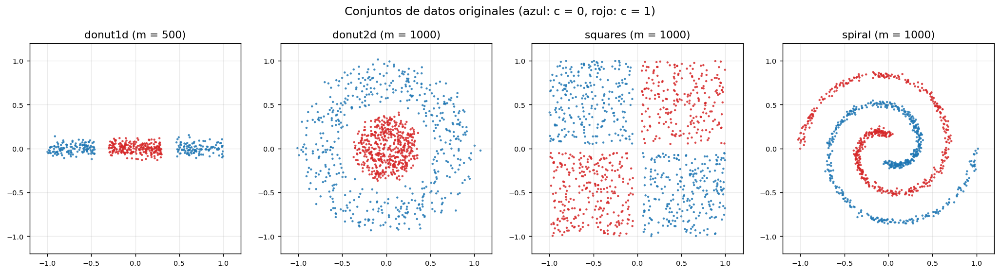

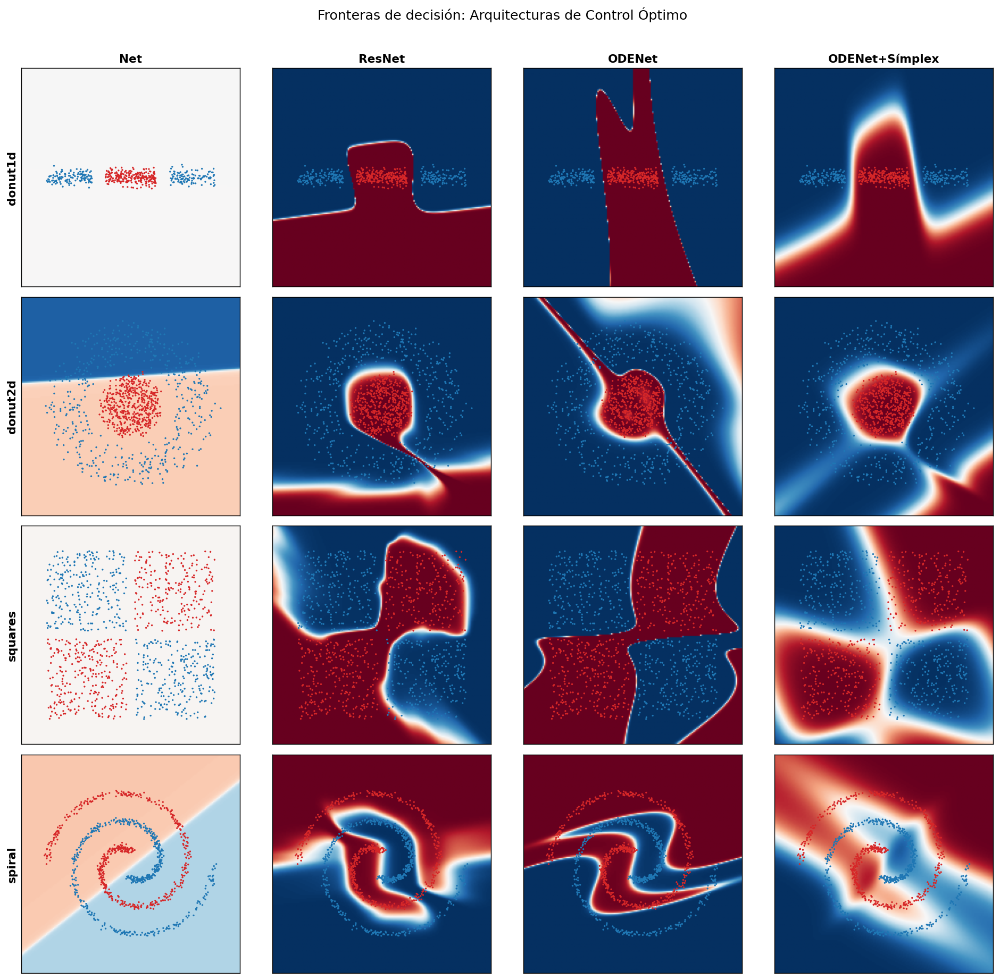

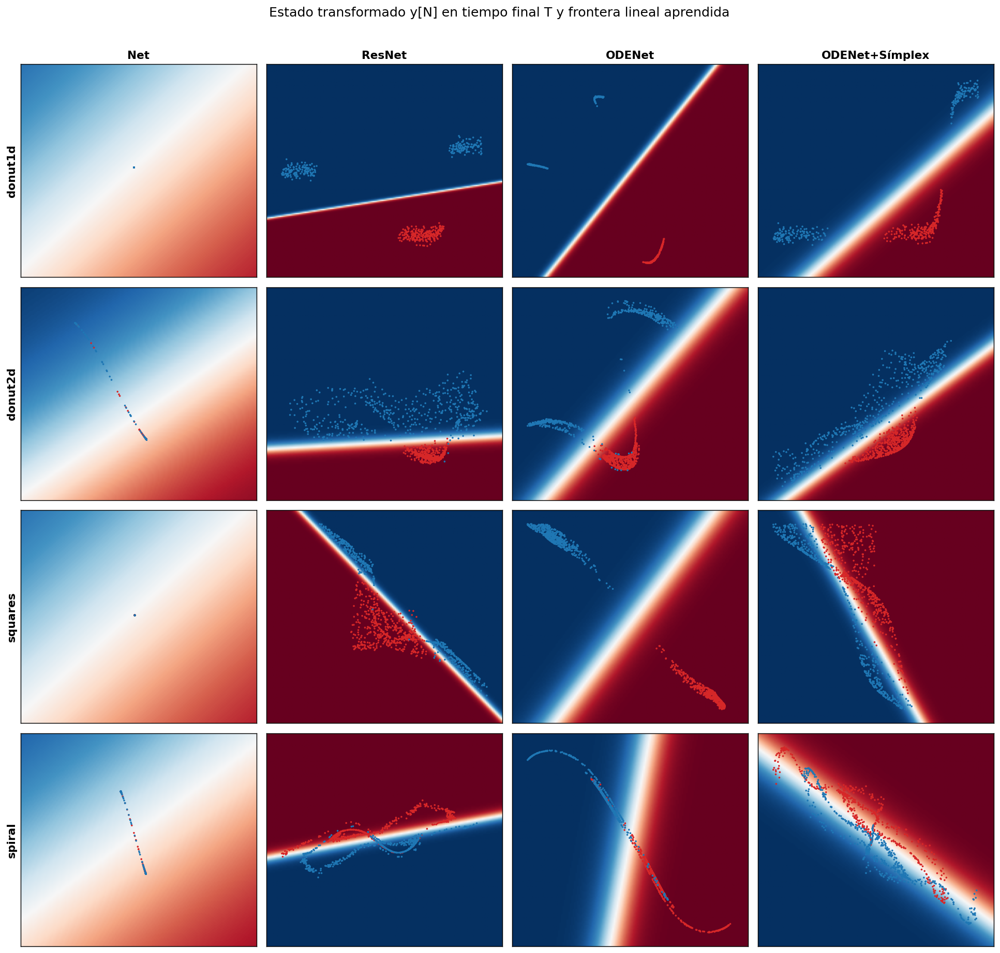

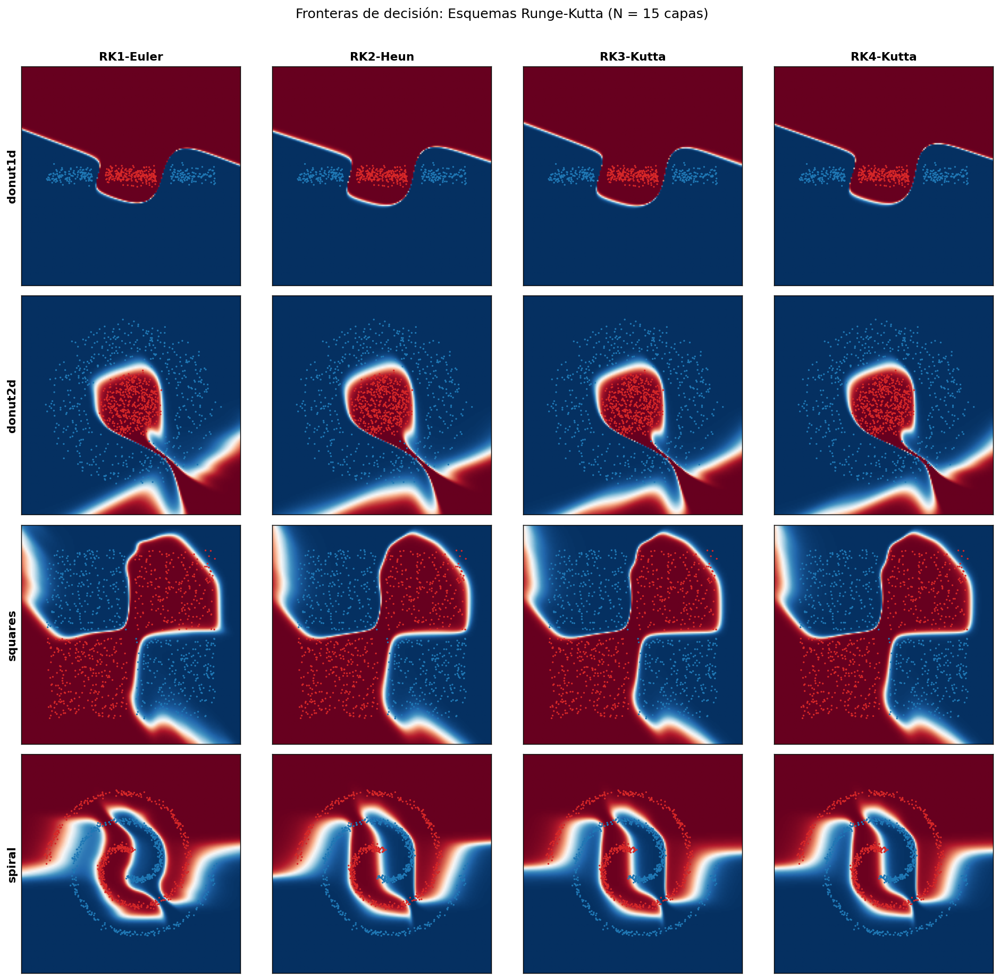

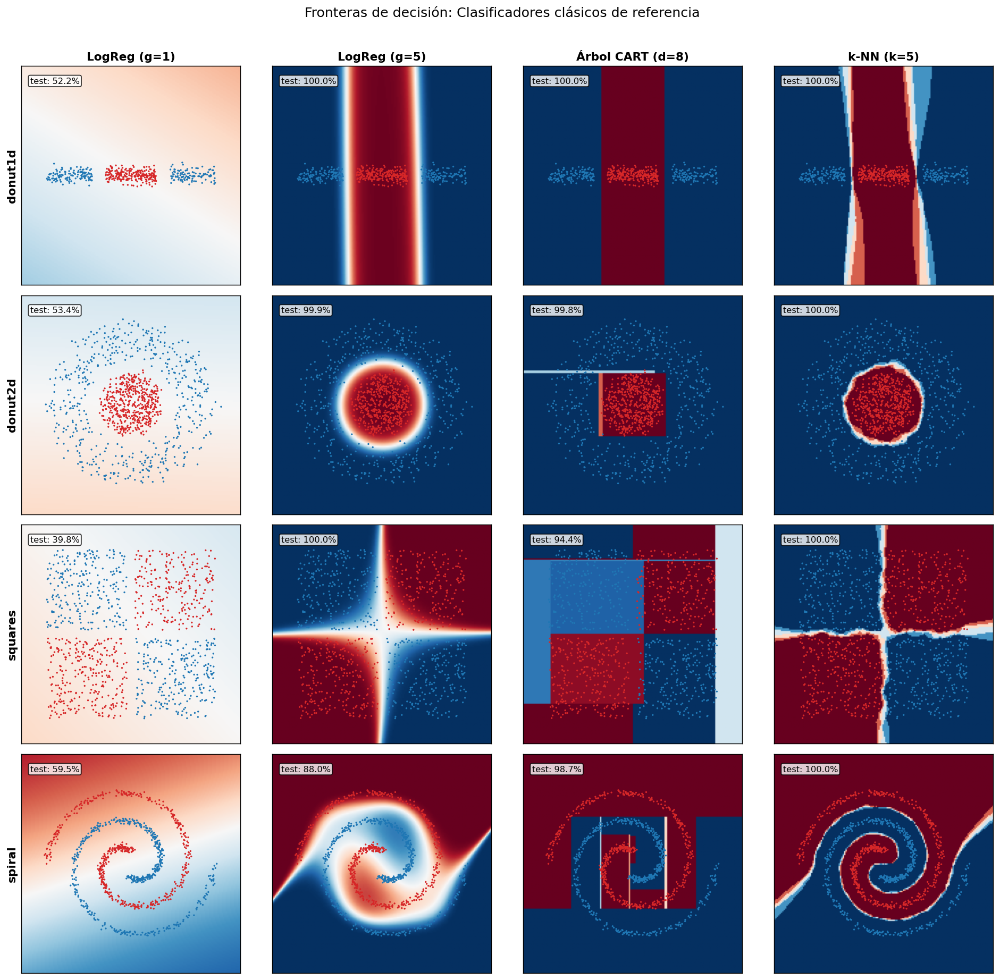

### 2. Detalle por dataset: evolución capa a capa, convergencia y pasos de tiempo

#### Dataset: `donut1d`

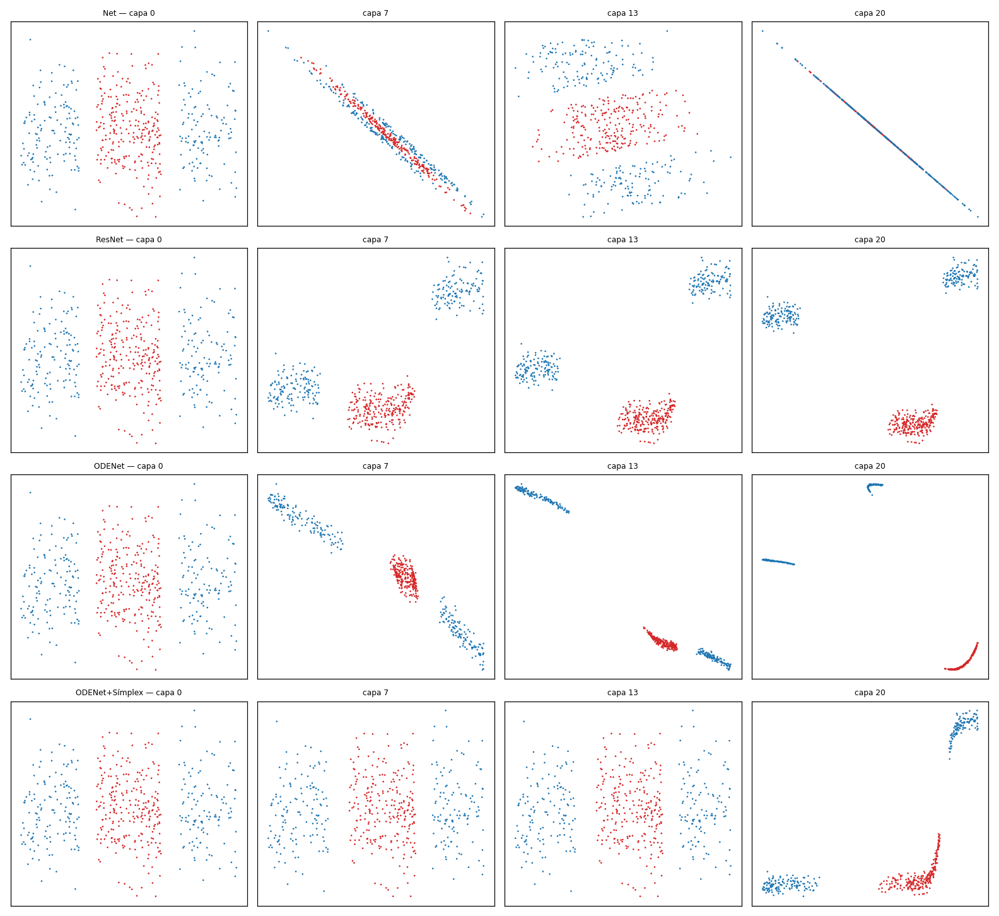

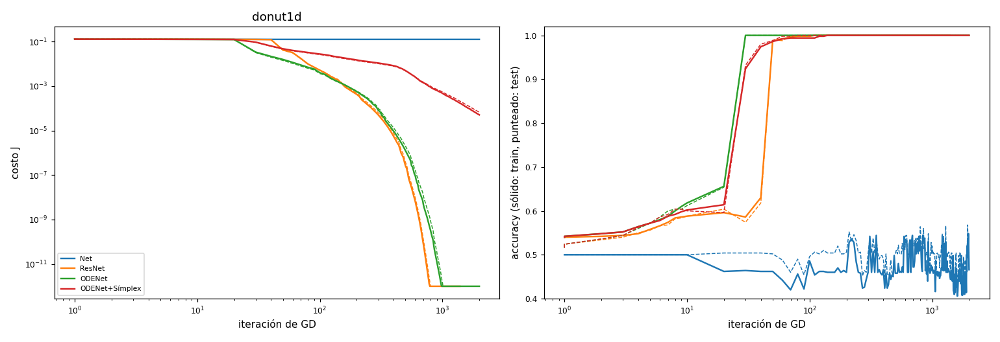

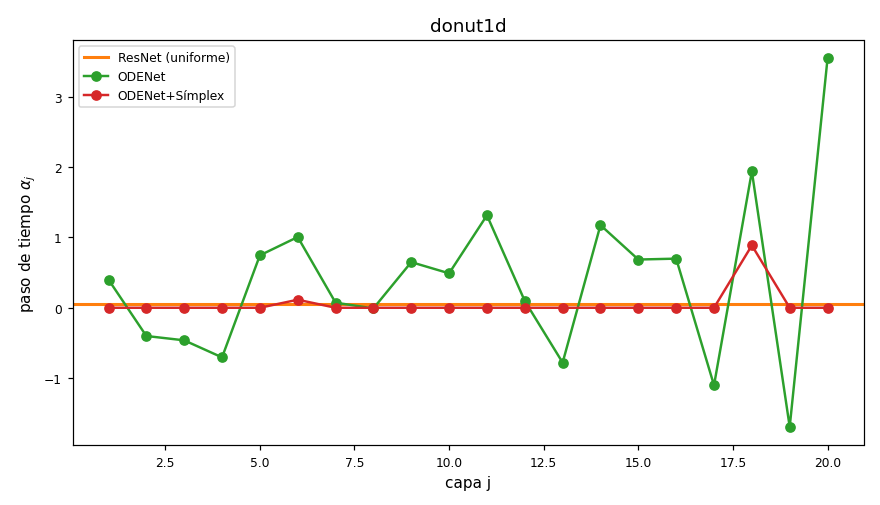

#### Dataset: `donut2d`

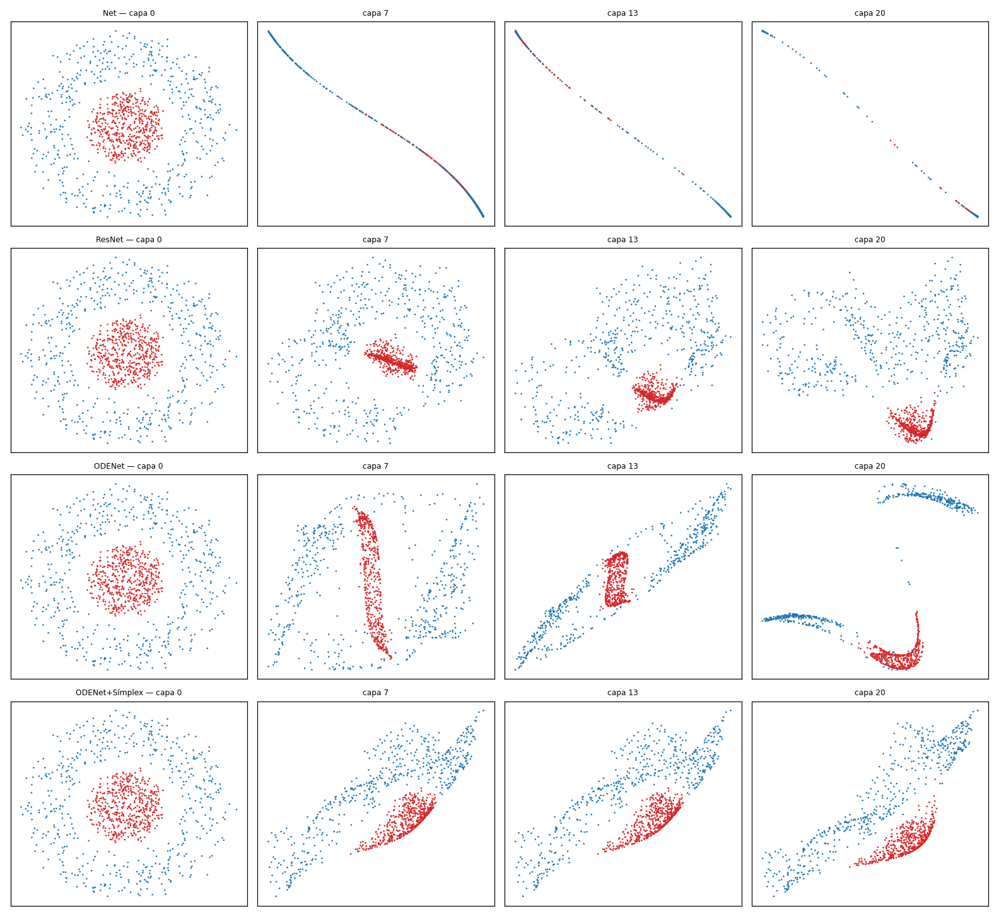

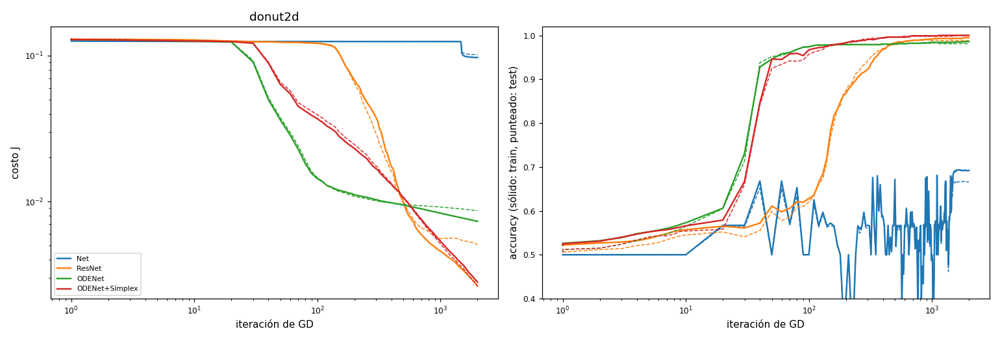

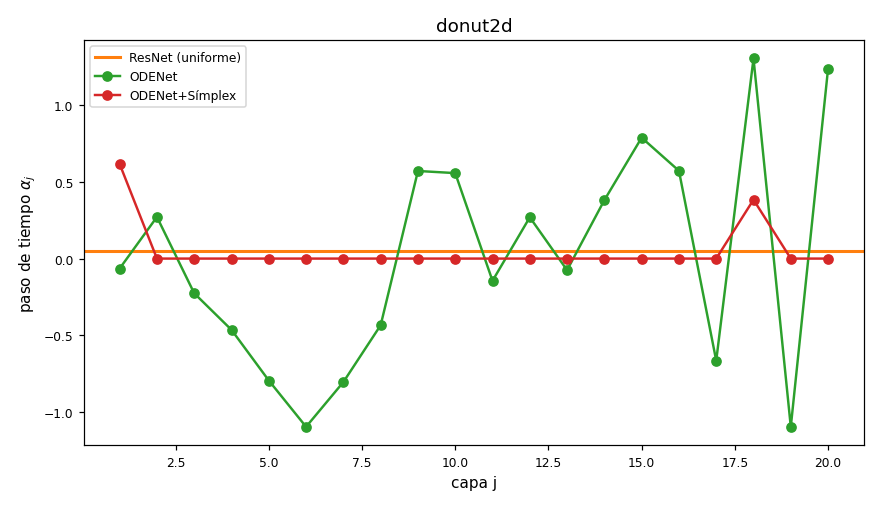

#### Dataset: `squares`

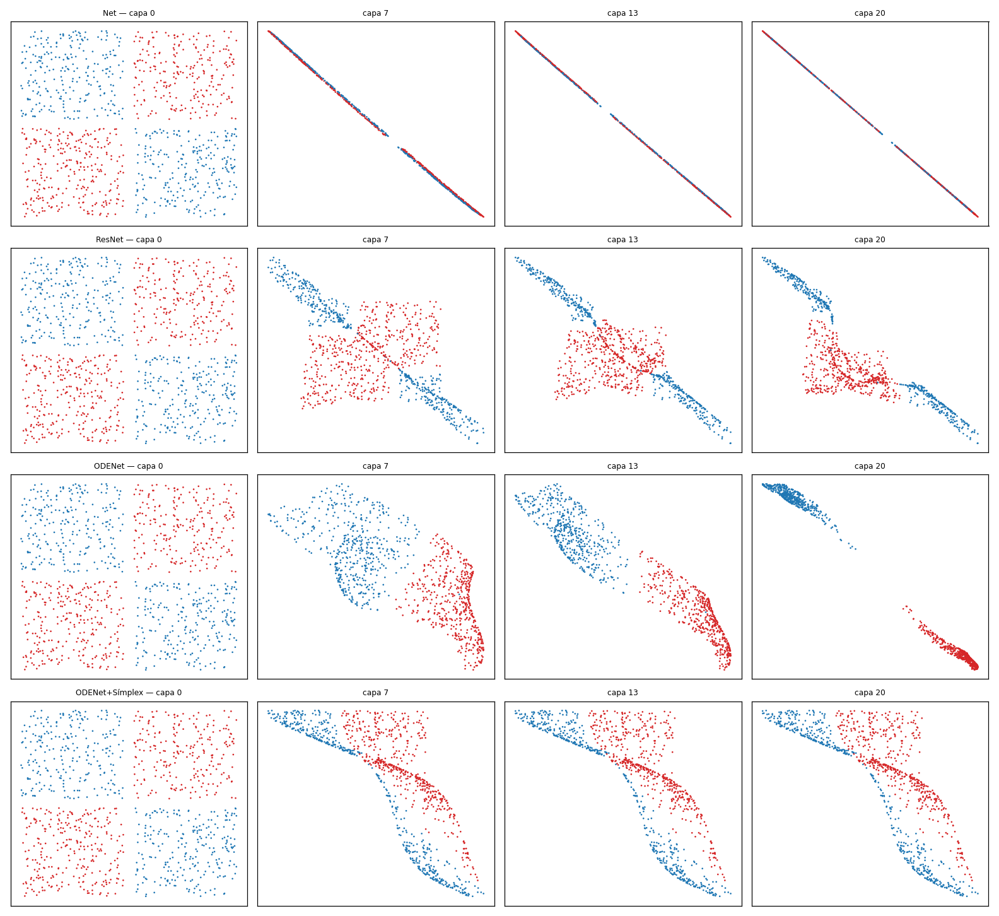

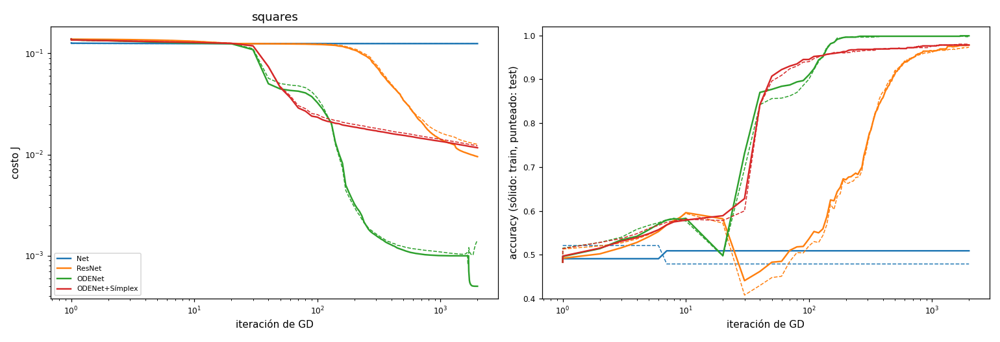

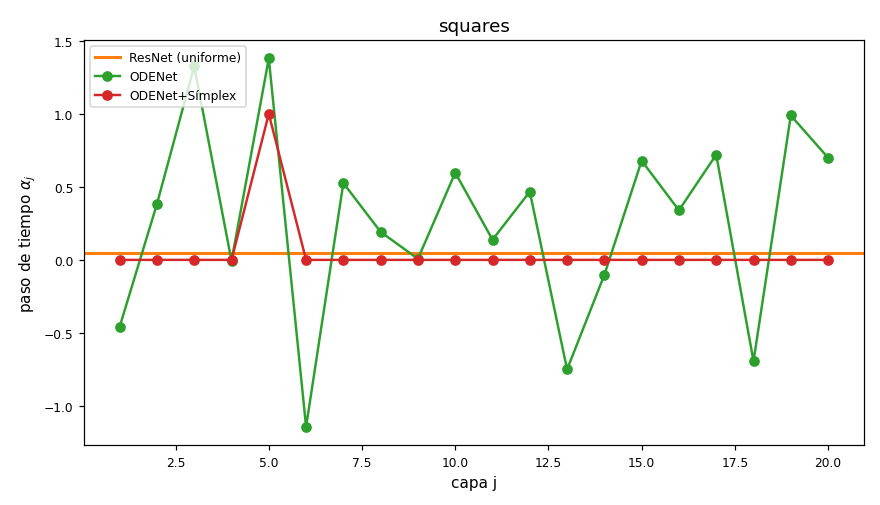

#### Dataset: `spiral`

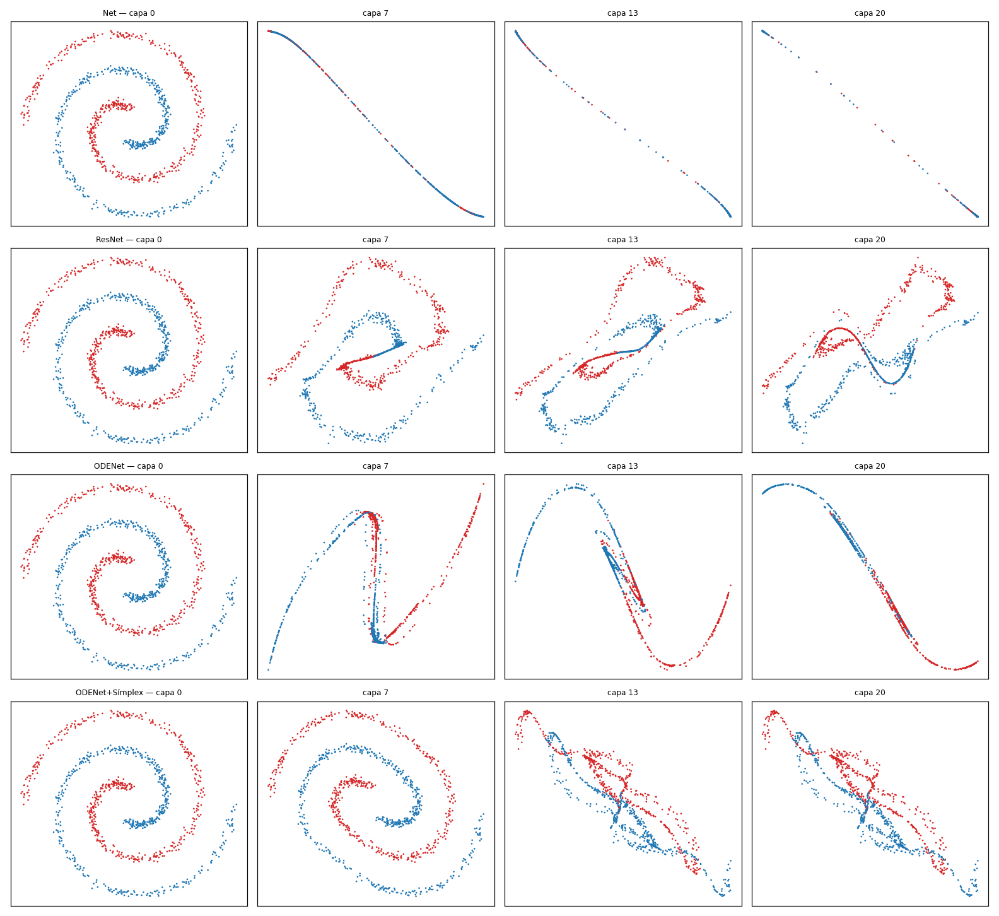

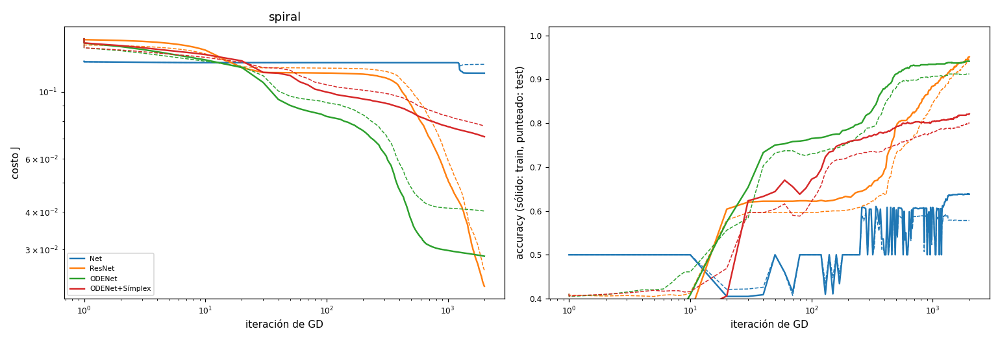

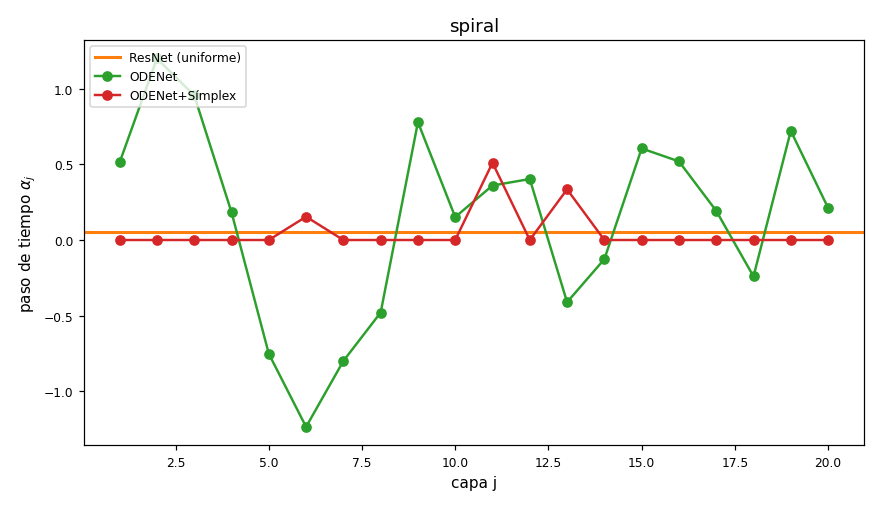

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

resdir = os.path.join(os.getcwd(), "results")
figdir = os.path.join(resdir, "figs")
os.makedirs(figdir, exist_ok=True)

METODOS = dict(ode_methods())
ARQ = ["Net", "ResNet", "ODENet", "ODENet+Simplex"]
RK = ["RK1-Euler", "RK2-Heun", "RK3-Kutta", "RK4-Kutta"]
TITULO = {"ODENet+Simplex": "ODENet+Símplex"}
col = lambda c: np.where(c > 0.5, "#d62728", "#1f77b4")


def cargar(d, m):
    return METODOS[m](), load_theta(os.path.join(resdir, f"theta_{d}_{slug(m)}.csv"))


def plot_datasets_originales():
    fig, axs = plt.subplots(1, 4, figsize=(16, 4))
    for ax, d in zip(axs, DATASET_NAMES):
        Xtr, ctr, _, _ = get_data(d, 1)
        ax.scatter(Xtr[0], Xtr[1], c=col(ctr), s=6, alpha=0.85, linewidths=0)
        ax.set_title(f"{d} (m = {Xtr.shape[1]})", fontsize=12)
        ax.set_xlim(-1.2, 1.2)
        ax.set_ylim(-1.2, 1.2)
        ax.set_aspect("equal")
        ax.grid(True, alpha=0.25)
    fig.suptitle("Conjuntos de datos originales (azul: c = 0, rojo: c = 1)", fontsize=13, y=1.02)
    fig.tight_layout()
    out = os.path.join(figdir, "datasets_originales.png")
    fig.savefig(out, dpi=130, bbox_inches="tight")
    plt.close(fig)
    return out


def plot_grid_ode(metodos, nombre_archivo, titulo_general, lim=1.3, res=160):
    xs = np.linspace(-lim, lim, res)
    GX, GY = np.meshgrid(xs, xs)
    grid = np.vstack([GX.ravel(), GY.ravel()])

    fig, axs = plt.subplots(len(DATASET_NAMES), len(metodos), figsize=(15, 14))
    for r, d in enumerate(DATASET_NAMES):
        Xtr, ctr, _, _ = get_data(d, 1)
        for c_idx, m in enumerate(metodos):
            ax = axs[r, c_idx]
            M, th = cargar(d, m)
            Z = predict_prob(M, th, grid).reshape(res, res)
            ax.imshow(Z, extent=(-lim, lim, -lim, lim), origin="lower", cmap="RdBu_r", vmin=0, vmax=1)
            ax.scatter(Xtr[0], Xtr[1], c=col(ctr), s=3.5, linewidths=0)
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0:
                ax.set_title(TITULO.get(m, m), fontsize=12, fontweight="bold")
            if c_idx == 0:
                ax.set_ylabel(d, fontsize=12, fontweight="bold")
    fig.suptitle(titulo_general, fontsize=14, y=1.01)
    fig.tight_layout()
    out = os.path.join(figdir, nombre_archivo)
    fig.savefig(out, dpi=130, bbox_inches="tight")
    plt.close(fig)
    return out


def plot_grid_transformacion_final(metodos, nombre_archivo, res=160):
    fig, axs = plt.subplots(len(DATASET_NAMES), len(metodos), figsize=(15, 14))
    for r, d in enumerate(DATASET_NAMES):
        Xtr, ctr, _, _ = get_data(d, 1)
        for c_idx, m in enumerate(metodos):
            ax = axs[r, c_idx]
            M, th = cargar(d, m)
            YN = layer_states(M, th, Xtr)[-1]
            lim_x = max(1.3, float(np.max(np.abs(YN[0]))) * 1.15)
            lim_y = max(1.3, float(np.max(np.abs(YN[1]))) * 1.15)
            xs = np.linspace(-lim_x, lim_x, res)
            ys = np.linspace(-lim_y, lim_y, res)
            GX, GY = np.meshgrid(xs, ys)
            Z = head(M, th, np.vstack([GX.ravel(), GY.ravel()])).reshape(res, res)
            ax.imshow(Z, extent=(-lim_x, lim_x, -lim_y, lim_y), origin="lower",
                      aspect="auto", cmap="RdBu_r", vmin=0, vmax=1)
            ax.scatter(YN[0], YN[1], c=col(ctr), s=4, linewidths=0)
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0:
                ax.set_title(TITULO.get(m, m), fontsize=12, fontweight="bold")
            if c_idx == 0:
                ax.set_ylabel(d, fontsize=12, fontweight="bold")
    fig.suptitle("Estado transformado y[N] en tiempo final T y frontera lineal aprendida", fontsize=14, y=1.01)
    fig.tight_layout()
    out = os.path.join(figdir, nombre_archivo)
    fig.savefig(out, dpi=130, bbox_inches="tight")
    plt.close(fig)
    return out


def plot_grid_baselines(lim=1.3, res=160):
    baselines = [
        ("LogReg (g=1)", lambda: LogReg(degree=1)),
        ("LogReg (g=5)", lambda: LogReg(degree=5)),
        ("Árbol CART (d=8)", lambda: DecisionTree(max_depth=8, min_leaf=5)),
        ("k-NN (k=5)", lambda: KNN(k=5)),
    ]
    xs = np.linspace(-lim, lim, res)
    GX, GY = np.meshgrid(xs, xs)
    grid = np.vstack([GX.ravel(), GY.ravel()])

    fig, axs = plt.subplots(len(DATASET_NAMES), len(baselines), figsize=(15, 14))
    for r, d in enumerate(DATASET_NAMES):
        Xtr, ctr, Xte, cte = get_data(d, 1)
        for c_idx, (bname, ctor) in enumerate(baselines):
            ax = axs[r, c_idx]
            mdl = ctor().fit(Xtr, ctr)
            Z = mdl.prob(grid).reshape(res, res)
            acc = prob_acc(mdl.prob(Xte), cte)
            ax.imshow(Z, extent=(-lim, lim, -lim, lim), origin="lower", cmap="RdBu_r", vmin=0, vmax=1)
            ax.scatter(Xtr[0], Xtr[1], c=col(ctr), s=3.5, linewidths=0)
            ax.set_xticks([]); ax.set_yticks([])
            ax.text(0.04, 0.92, f"test: {acc:.1%}", transform=ax.transAxes, fontsize=9,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
            if r == 0:
                ax.set_title(bname, fontsize=12, fontweight="bold")
            if c_idx == 0:
                ax.set_ylabel(d, fontsize=12, fontweight="bold")
    fig.suptitle("Fronteras de decisión: Clasificadores clásicos de referencia", fontsize=14, y=1.01)
    fig.tight_layout()
    out = os.path.join(figdir, "grid_pred_baselines.png")
    fig.savefig(out, dpi=130, bbox_inches="tight")
    plt.close(fig)
    return out


p_orig = plot_datasets_originales()
p_arq = plot_grid_ode(ARQ, "grid_pred_arquitecturas.png", "Fronteras de decisión: Arquitecturas de Control Óptimo")
p_trf = plot_grid_transformacion_final(ARQ, "grid_transf_final_arquitecturas.png")
p_rk  = plot_grid_ode(RK, "grid_pred_rk.png", "Fronteras de decisión: Esquemas Runge-Kutta (N = 15 capas)")
p_bas = plot_grid_baselines()

# Mostrar todo en pantalla
display(Markdown("### 1. Problemas originales y comparativas globales (todos los casos)"))
for path in [p_orig, p_arq, p_trf, p_rk, p_bas]:
    display(Image(path))

display(Markdown("### 2. Detalle por dataset: evolución capa a capa, convergencia y pasos de tiempo"))
for d in DATASET_NAMES:
    display(Markdown(f"#### Dataset: `{d}`"))
    for fname in [
        f"transf_{d}_arquitecturas.png",
        f"hist_{d}_arquitecturas.png",
        f"alpha_{d}.png",
    ]:
        fpath = os.path.join(figdir, fname)
        if os.path.exists(fpath):
            display(Image(fpath))